In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.ndimage import gaussian_filter
from scipy.io import loadmat
from pathlib import Path
from matplotlib.patches import Rectangle
import re
import os


if os.getcwd().endswith('scripts'):
    os.chdir('..')
os.getcwd()

'/Users/arthur/git/Master amu/DA3_VSDI_S1_G1_2026_catz'

In [3]:
## load the condition
## condition is the order of the finger stimulations

condition_load = np.load('data/New_list_conditions.npy')
condition = []

for i in condition_load[0::2]:
    cond = re.split('_', str(i))[0]
    condition.append(cond[-1])

condition = np.array(condition)

### Extract data

In [4]:
# parameters
sig = 1 ## for the gaussian filter

In [5]:
## extract data from trials

data_dir = Path('/Users/arthur/git/Master amu/DA3_VSDI_S1_G1_2026/data') ## put your own path
Cortex = np.load('data/Image_Cortex.npy')  
x = np.arange(1, 31, 1)

delta_f = []

for trial_num in x:
    stim = np.load(data_dir / f'Trial_{trial_num}_Stim.npy')
    control = np.load(data_dir / f'Trial_{trial_num}_Control.npy')

    df = (stim - control)/control
    delta_f.append(df)

delta_f = np.array(delta_f)

df_filtered = gaussian_filter(delta_f.copy(), sigma=(0, sig, sig, 0)) 
# df_test = gaussian_filter(delta_f.copy(), sigma=(0, sig, sig, sig))

FileNotFoundError: [Errno 2] No such file or directory: '/Users/arthur/git/Master amu/DA3_VSDI_S1_G1_2026/data/Trial_1_Stim.npy'

In [ ]:
cond1_index = np.where(condition == '1')[0]
cond2_index = np.where(condition == '2')[0]
cond3_index = np.where(condition == '3')[0]

Text(0, 0.5, 'finger 4')

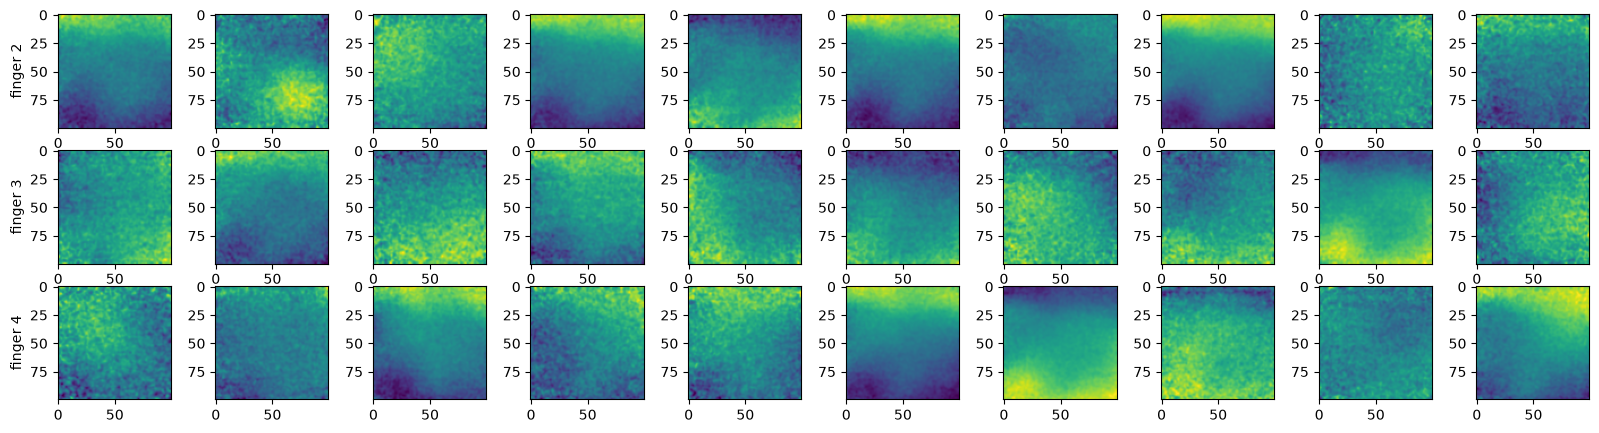

In [106]:
slice = 35

fig, ax = plt.subplots(3, 10, figsize=(20,5))


for i in range(10):
    ax[0][i].imshow(df_filtered[cond1_index][i,:,:,slice])
    ax[1][i].imshow(df_filtered[cond2_index][i,:,:,slice])
    ax[2][i].imshow(df_filtered[cond3_index][i,:,:,slice])


ax[0][0].set_ylabel('finger 2')
ax[1][0].set_ylabel('finger 3')
ax[2][0].set_ylabel('finger 4')

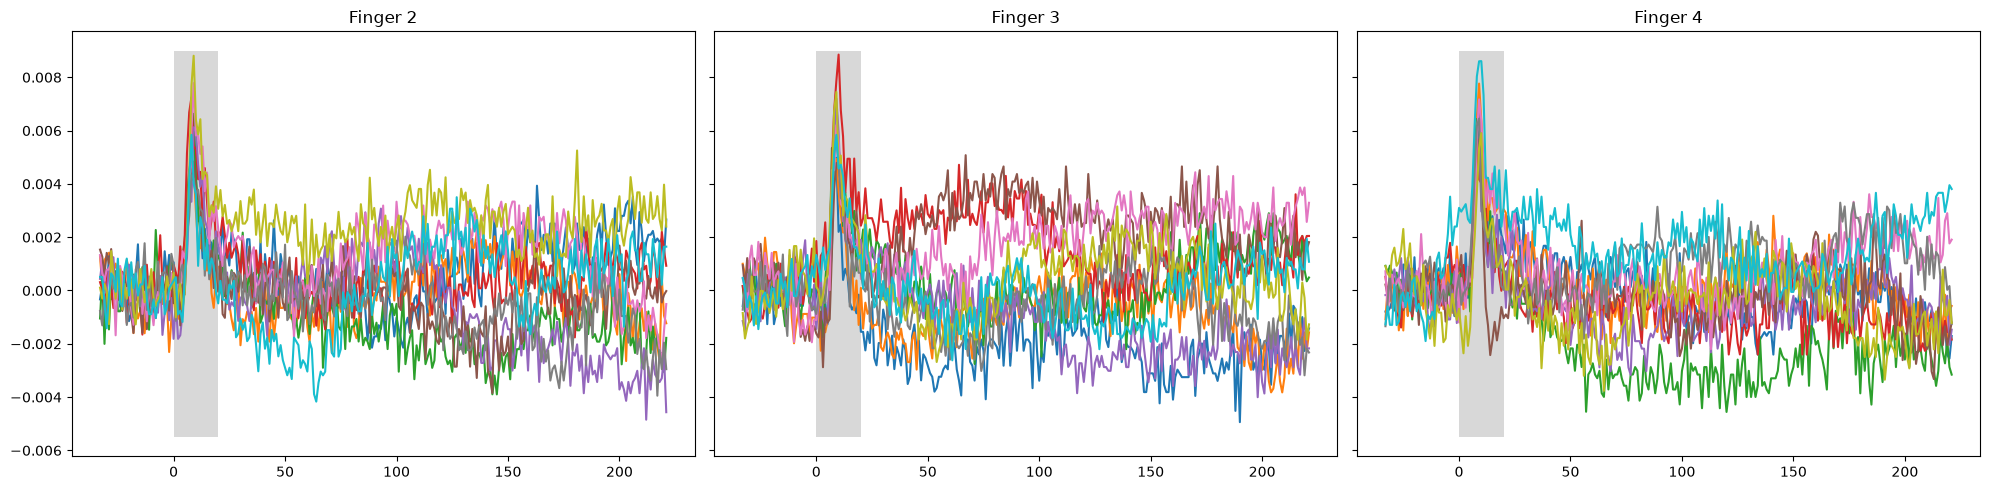

In [63]:
fig, ax = plt.subplots(1, 3, figsize=(20, 5), sharey=True)
x = np.arange(-33, 222, 1)

for i in range(10):
    ax[0].plot(x, delta_f[cond1_index[i]][50,80,:])
    ax[1].plot(x, delta_f[cond2_index[i]][50,80,:])
    ax[2].plot(x, delta_f[cond3_index[i]][50,80,:])

ax[0].set_title('Finger 2')
ax[1].set_title('Finger 3')
ax[2].set_title('Finger 4')

# ax = plt.gca()
ax[0].add_patch(Rectangle((0, -0.0055), 20, .0145, facecolor="grey", alpha=0.3))
ax[1].add_patch(Rectangle((0, -0.0055), 20, .0145, facecolor="grey", alpha=0.3))
ax[2].add_patch(Rectangle((0, -0.0055), 20, .0145, facecolor="grey", alpha=0.3))

plt.tight_layout()

#### Thresholding technique
- half-maximal S1 response amplitude contours were computed from Gaussianfiltered VSD images at 10-14 ms after the stimulus.

##### Steps
1. apply gaussian filter
2. take the mean for each finger, per frame
3. take take the maximum activity of the averaged activity
4. threshold frames

In [185]:
def extract_thresh(data, thresh):
    max_flu = []
    
    for i in data:
        max_flu.append(np.max(i[:,:,33:40])*thresh)

    return max_flu

In [186]:
max_flu = extract_thresh(df_filtered, 0.5)

In [ ]:
df_thresh = []

for i, rec in enumerate(df_filtered):
    temp = []

    df_thresh.append(rec > max_flu[i])

df_thresh = np.array(df_thresh)

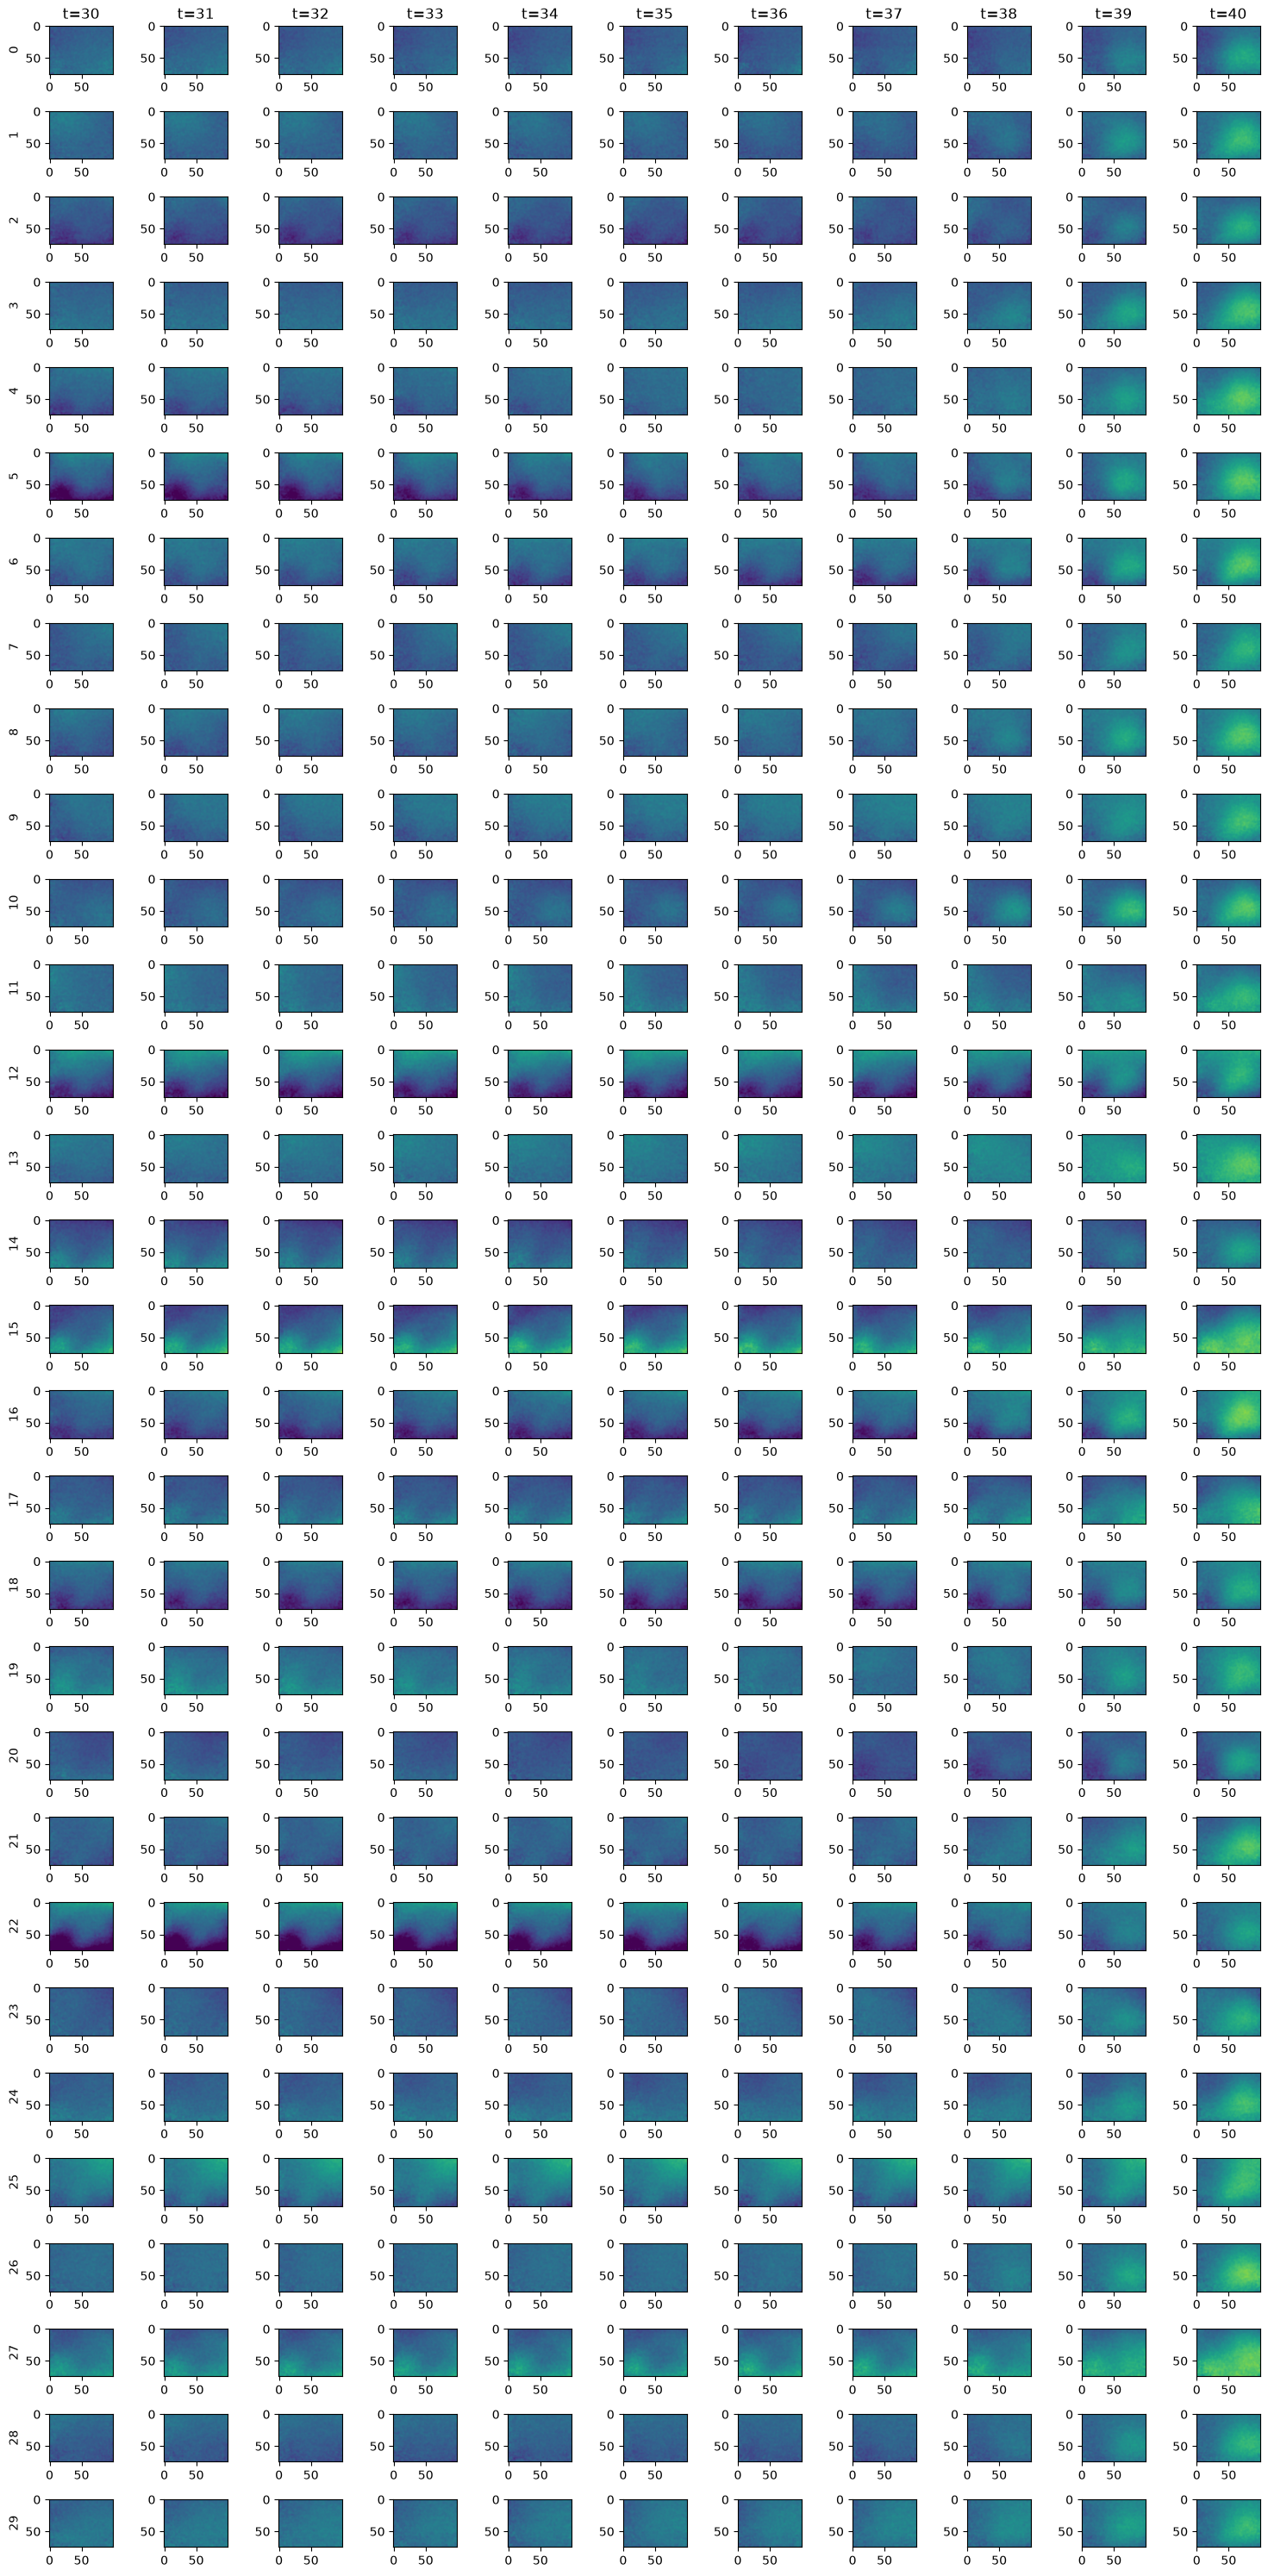

In [188]:
fig, ax = plt.subplots(30, 11, figsize=(15, 30))
slice = 14
start = 30

for i in range(30):
        for j in range(11):
            ax[i][j].imshow(df_filtered[i][25:,:,start+j], vmin=-0.005, vmax=0.01)
            if i == 0:
                  ax[i][j].set_title(f't={start+j}')
            if j == 0:
                  ax[i][j].set_ylabel(i)



plt.tight_layout()

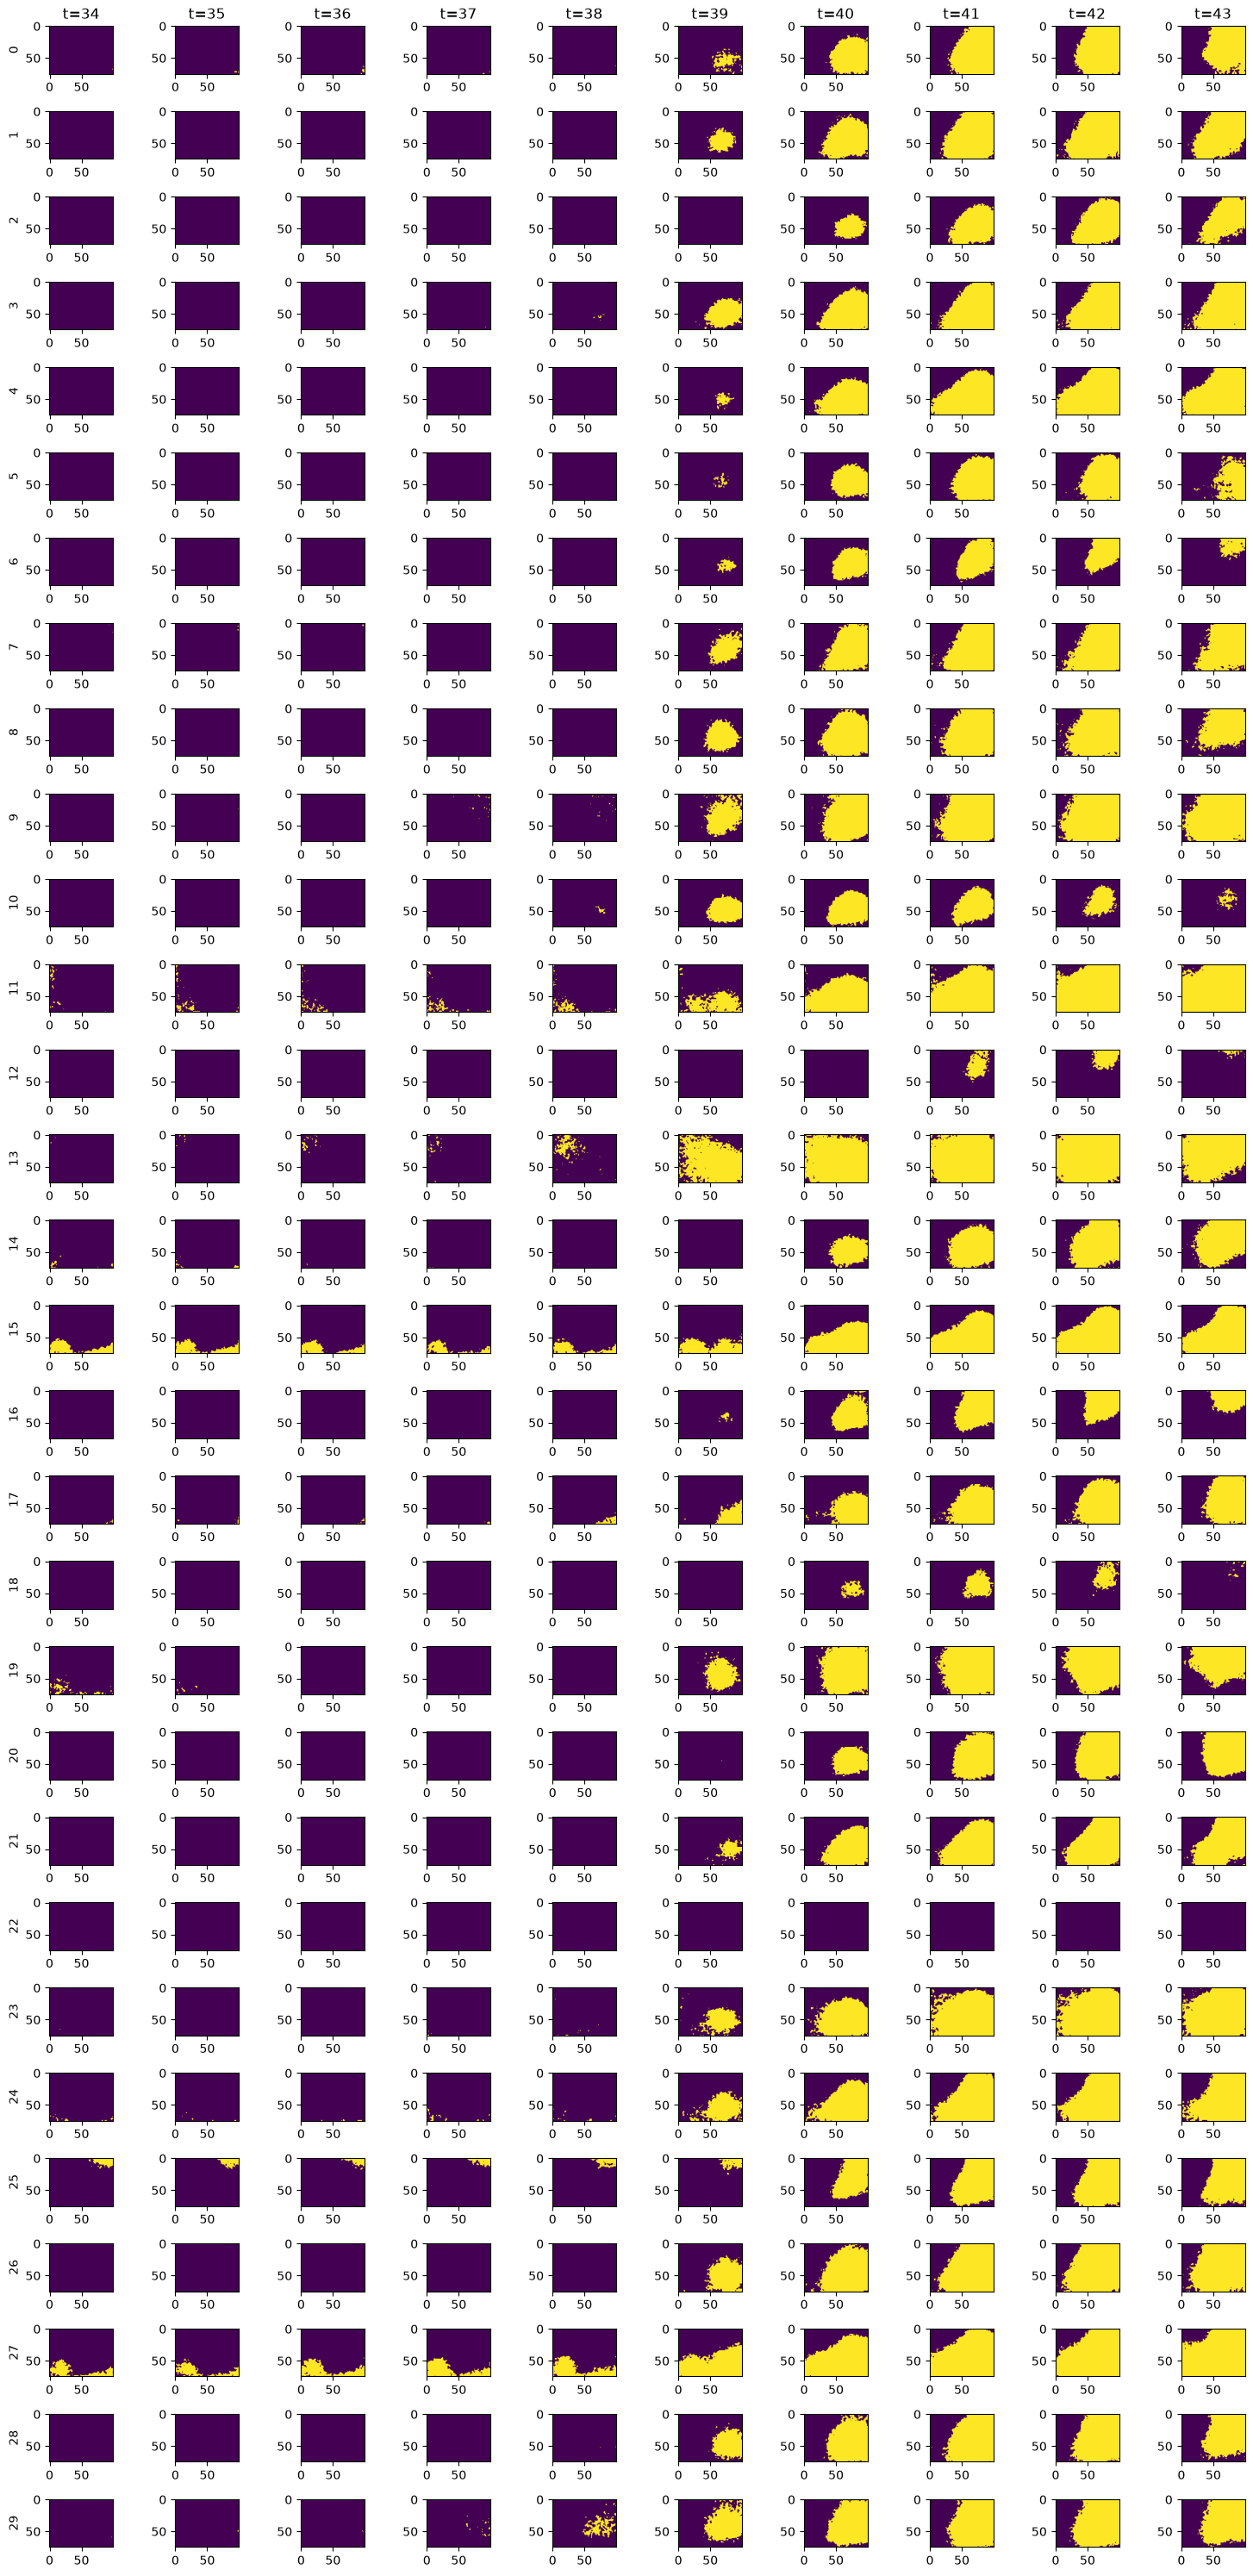

In [189]:
fig, ax = plt.subplots(30, 10, figsize=(15, 30))
slice = 14
start = 34

for i in range(30):
        for j in range(10):
            ax[i][j].imshow(df_thresh[i][25:,:,start+j])
            if i == 0:
                  ax[i][j].set_title(f't={start+j}')
            if j == 0:
                  ax[i][j].set_ylabel(i)



plt.tight_layout()

In [17]:
first_stim = []

for slice in df_thresh[:,:,:,38:41]:
    for j in range(3):
        if np.mean(slice[:,:,j]) > 0:
            first_stim.append(slice[:,:,j])
            break

first_stim = np.array(first_stim)

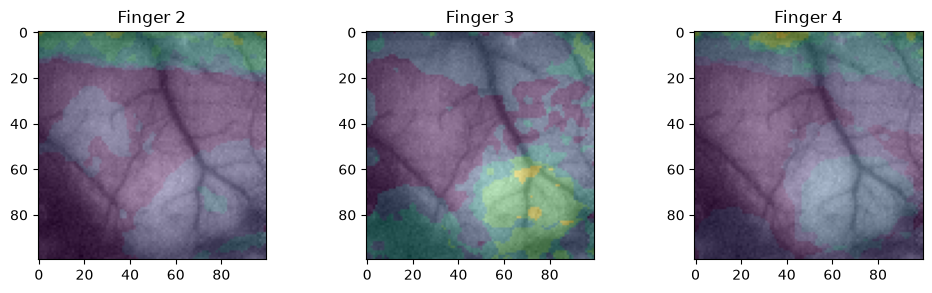

In [55]:
cond1_ave = np.mean(first_stim[cond1_index], axis=0)
cond2_ave = np.mean(first_stim[cond2_index], axis=0)
cond3_ave = np.mean(first_stim[cond3_index], axis=0)

fig, ax = plt.subplots(1, 3, figsize=(10, 3))

ax[0].imshow(cond1_ave)
ax[1].imshow(cond2_ave)
ax[2].imshow(cond3_ave)

ax[0].imshow(Cortex, alpha=0.6)
ax[1].imshow(Cortex, alpha=0.6)
ax[2].imshow(Cortex, alpha=0.6)

ax[0].set_title('Finger 2')
ax[1].set_title('Finger 3')
ax[2].set_title('Finger 4')

plt.tight_layout()

In [57]:
cond1_ave = np.mean(df_thresh[cond1_index], axis=0)
cond2_ave = np.mean(df_thresh[cond2_index], axis=0)
cond3_ave = np.mean(df_thresh[cond3_index], axis=0)

Text(0, 0.5, 'finger 4')

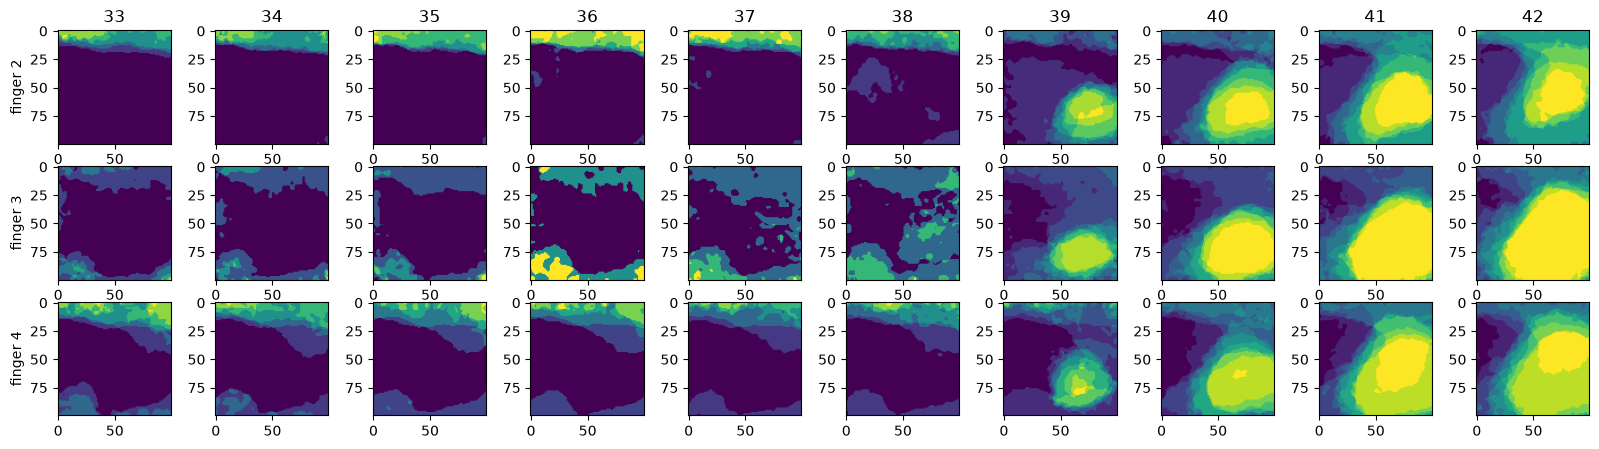

In [64]:
fig, ax = plt.subplots(3, 10, figsize=(20,5))

for i in range(10):
    ax[0][i].imshow(cond1_ave[:,:,33+i])
    ax[1][i].imshow(cond2_ave[:,:,33+i])
    ax[2][i].imshow(cond3_ave[:,:,33+i])

    ax[0][i].set_title(33+i)

ax[0][0].set_ylabel('finger 2')
ax[1][0].set_ylabel('finger 3')
ax[2][0].set_ylabel('finger 4')

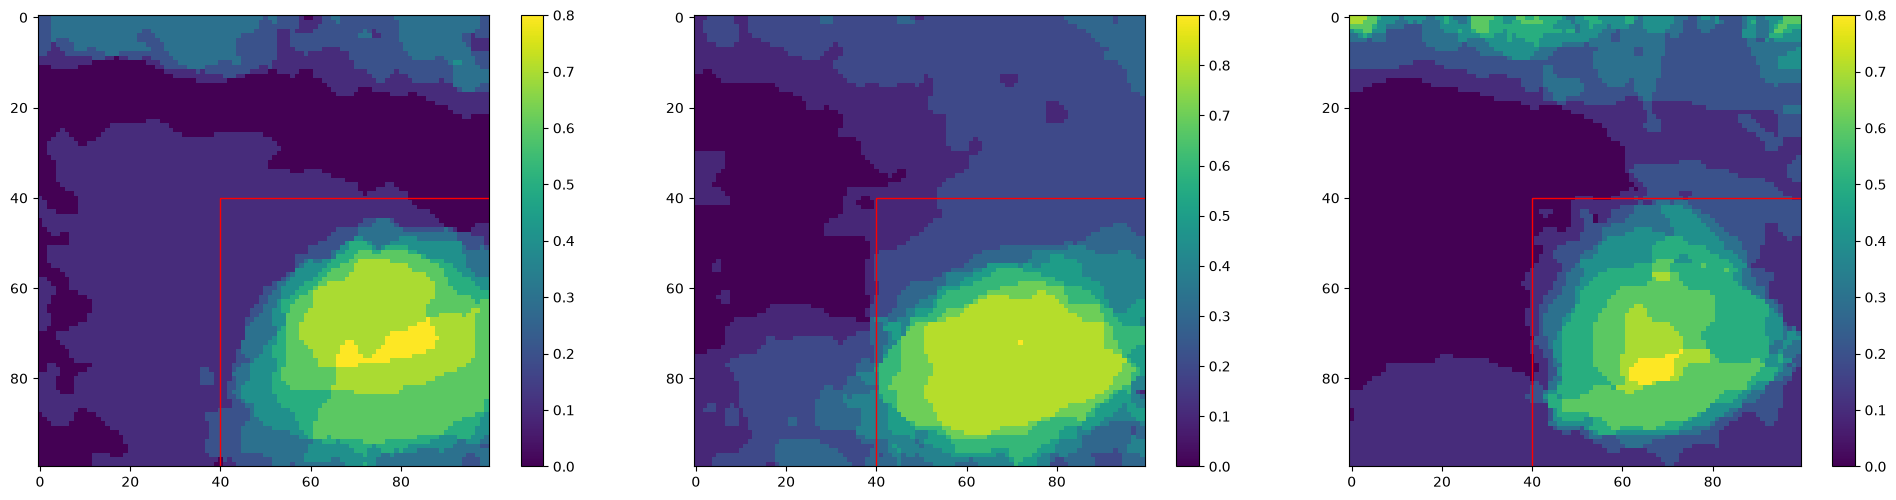

In [65]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(20, 5))
im1 = ax1.imshow(cond1_ave[:,:,39])
fig.colorbar(im1, ax=ax1)

im2 = ax2.imshow(cond2_ave[:,:,39])
fig.colorbar(im2, ax=ax2)

im3 = ax3.imshow(cond3_ave[:,:,39])
fig.colorbar(im3, ax=ax3)

ax1.add_patch(Rectangle((40, 100), 60, -60, fill=False, edgecolor='red'))
ax2.add_patch(Rectangle((40, 100), 60, -60, fill=False, edgecolor='red'))
ax3.add_patch(Rectangle((40, 100), 60, -60, fill=False, edgecolor='red'))

plt.tight_layout()

In [ ]:
roi1 = cond1_ave[40:,40:,39]
roi2 = cond2_ave[40:,40:,39]
roi3 = cond3_ave[40:,40:,39]

threshold=0.6

roi1[roi1 < threshold] = 0
roi2[roi2 < threshold] = 0
roi3[roi3 < threshold] = 0

In [ ]:
# roi1_min = roi1.min()
# roi1_max = roi1.max()
# roi1 = (roi1 - roi1_min) / (roi1_max - roi1_min)

# roi2_min = roi2.min()
# roi2_max = roi2.max()
# roi2 = (roi2 - roi2_min) / (roi2_max - roi2_min)

# roi3_min = roi3.min()
# roi3_max = roi3.max()
# roi3 = (roi3 - roi3_min) / (roi3_max - roi3_min)

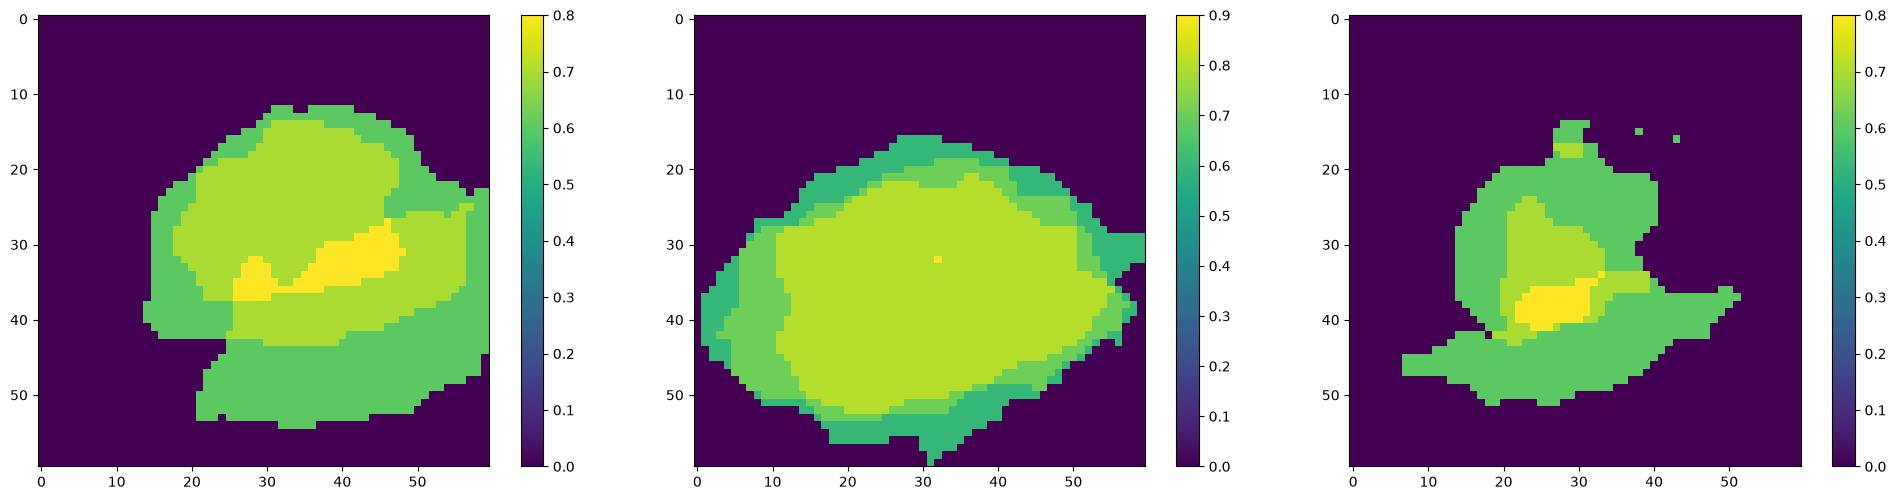

In [124]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(20, 5))
im1 = ax1.imshow(roi1[:,:])
fig.colorbar(im1, ax=ax1)

im2 = ax2.imshow(roi2[:,:])
fig.colorbar(im2, ax=ax2)

im3 = ax3.imshow(roi3[:,:])
fig.colorbar(im3, ax=ax3)

plt.tight_layout()

### Competition idea

In [138]:
pixel_overlap = []
for i in range(60):
    row = []
    for j in range(60):
        if roi1[i][j] != 0 and roi2[i][j] != 0 and roi3[i][j] != 0:
            if roi1[i][j] > roi2[i][j] and roi1[i][j] > roi3[i][j]:
                row.append(1)
            elif roi2[i][j] > roi1[i][j] and roi2[i][j] > roi3[i][j]:
                row.append(2)
            elif roi3[i][j] > roi2[i][j] and roi3[i][j] > roi1[i][j]:
                row.append(3)
            else:
                row.append(4)
        else:
            row.append(0)
    pixel_overlap.append(row)

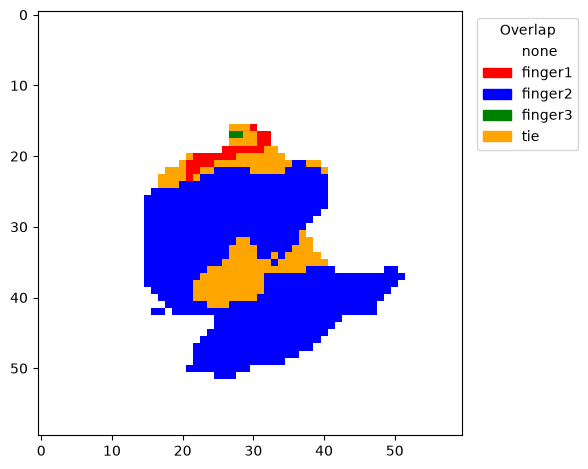

In [143]:
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap

colors = ['white', 'red', 'blue', 'green', 'orange']   # values 0, 1, 2, 3, 4
labels = ['none', 'finger1', 'finger2', 'finger3', 'tie']  # adjust to your trials

cmap = ListedColormap(colors)

fig, ax = plt.subplots()
ax.imshow(np.array(pixel_overlap), cmap=cmap, vmin=0, vmax=4, interpolation='nearest')

handles = [mpatches.Patch(color=c, label=l) for c, l in zip(colors, labels)]
ax.legend(handles=handles, bbox_to_anchor=(1.02, 1), loc='upper left', title='Overlap')

plt.tight_layout()
plt.show()

### Contrast Tests

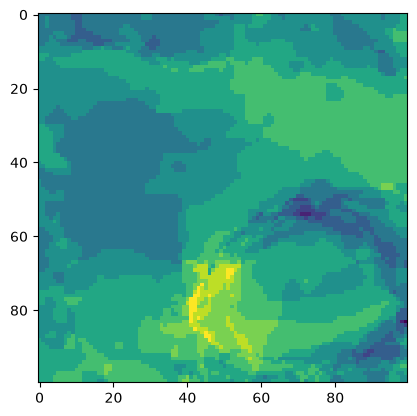

In [35]:
test = cond2_ave - cond1_ave
plt.imshow(test[:,:,39])

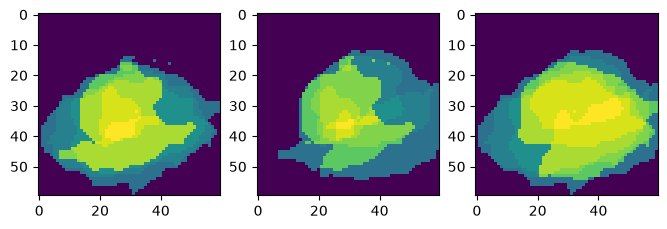

In [176]:
plt.figure(figsize=(8, 5))

plt.subplot(1,3,1)
plt.imshow(np.mean([roi2, roi3], axis=0))

plt.subplot(1,3,2)
plt.imshow(np.mean([roi1, roi3], axis=0))

plt.subplot(1,3,3)
plt.imshow(np.mean([roi1, roi2], axis=0))

plt.show()

In [155]:
d1_contrast = roi1 - np.mean([roi2, roi3], axis=0)
d2_contrast = roi2 - np.mean([roi1, roi3], axis=0)
d3_contrast = roi3 - np.mean([roi1, roi2], axis=0)

threshold=0.0
d1_contrast[d1_contrast < threshold] = 0
d2_contrast[d2_contrast < threshold] = 0
d3_contrast[d3_contrast < threshold] = 0

# total = cond1_ave + cond2_ave + cond3_ave

# d1_contrast = (cond1_ave - (cond2_ave + cond3_ave))/(total)
# d2_contrast = (cond2_ave - (cond1_ave + cond3_ave))/(total)
# d3_contrast = (cond3_ave - (cond1_ave + cond2_ave))/(total)

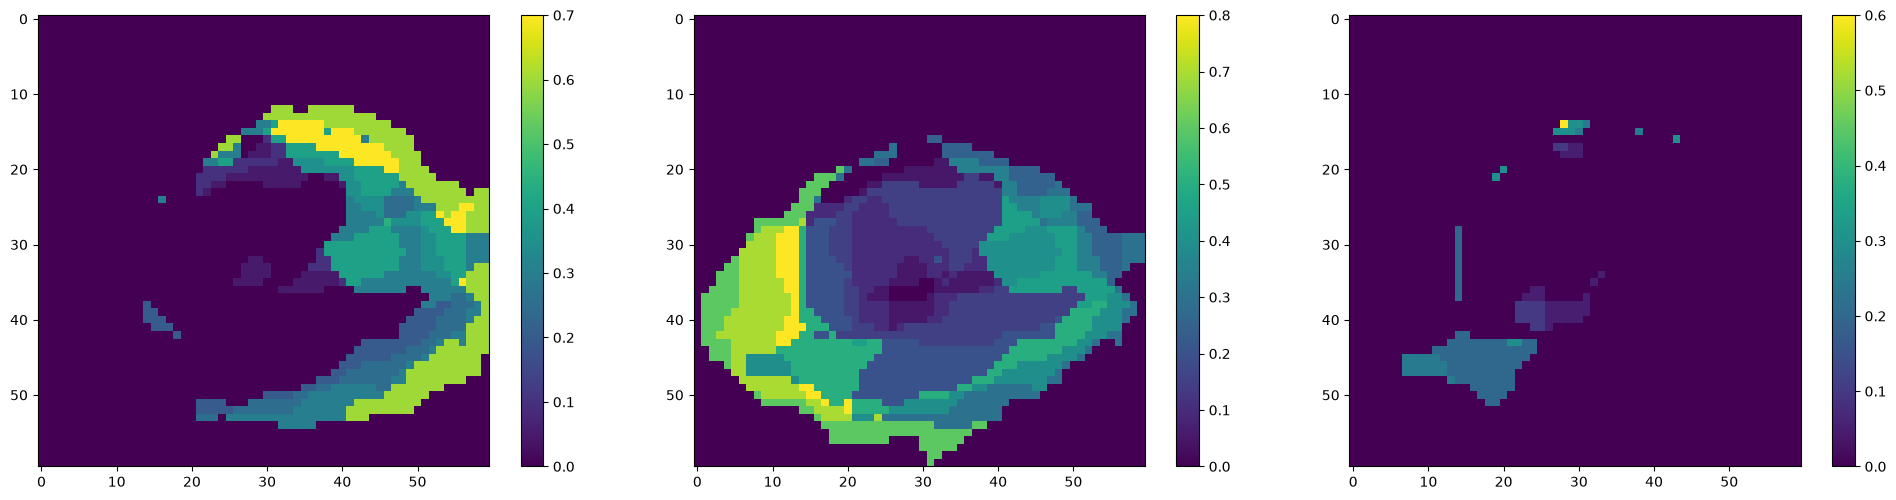

In [156]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(20, 5))
im1 = ax1.imshow(d1_contrast)
fig.colorbar(im1, ax=ax1)

im2 = ax2.imshow(d2_contrast)
fig.colorbar(im2, ax=ax2)

im3 = ax3.imshow(d3_contrast)
fig.colorbar(im3, ax=ax3)

plt.tight_layout()

### Finding the center

**it is clear from the threshold analysis above that the ROI is in the bottom right quandrant**

**therefore I will focus the analysis on this quandrant**

In [144]:
from cv2 import moments

center1 = None
center2 = None
center3 = None

M1 = moments(roi1)
M2 = moments(roi2)
M3 = moments(roi3)

center1 = (int(M1["m10"] / M1["m00"]), int(M1["m01"] / M1["m00"]))
center2 = (int(M2["m10"] / M2["m00"]), int(M2["m01"] / M2["m00"]))
center3 = (int(M3["m10"] / M3["m00"]), int(M3["m01"] / M3["m00"]))

center1, center2, center3

((37, 33), (29, 36), (27, 34))

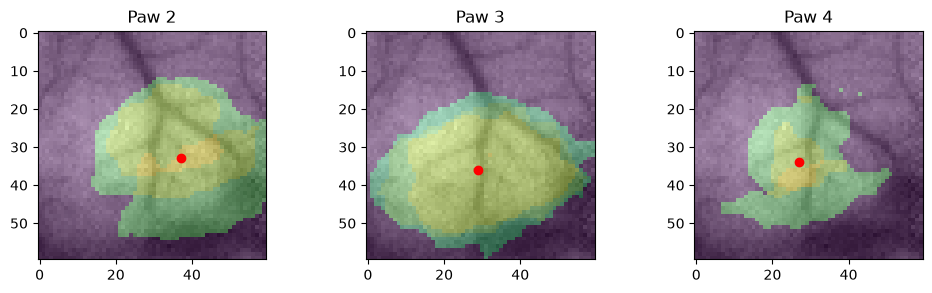

In [146]:
fig, ax = plt.subplots(1, 3, figsize=(10, 3))

ax[0].imshow(roi1)
ax[1].imshow(roi2)
ax[2].imshow(roi3)

ax[0].imshow(Cortex[40:,40:,:], alpha=0.6)
ax[1].imshow(Cortex[40:,40:,:], alpha=0.6)
ax[2].imshow(Cortex[40:,40:,:], alpha=0.6)

ax[0].plot(center1[0], center1[1], 'ro')
ax[1].plot(center2[0], center2[1], 'ro')
ax[2].plot(center3[0], center3[1], 'ro')

ax[0].set_title('Paw 2')
ax[1].set_title('Paw 3')
ax[2].set_title('Paw 4')

plt.tight_layout()

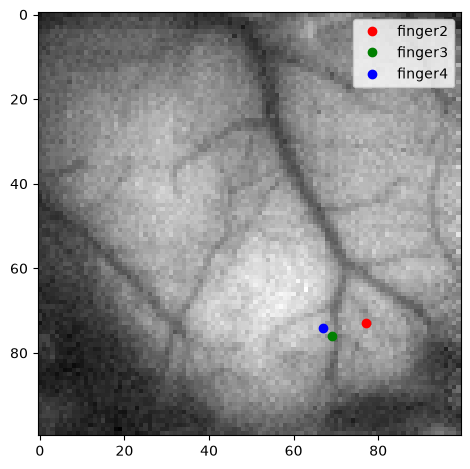

In [147]:
plt.imshow(Cortex)

plt.plot(center1[0]+40, center1[1]+40, 'ro', label='finger2')
plt.plot(center2[0]+40, center2[1]+40, 'go', label='finger3')
plt.plot(center3[0]+40, center3[1]+40, 'bo', label='finger4')

plt.legend()
plt.tight_layout()